In [1]:
!pip install kaggle tensorflow matplotlib scikit-learn opencv-python

In [15]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping


In [16]:
# Configure Kaggle API
kaggle_dir = Path.home() / '.kaggle'
kaggle_json_path = kaggle_dir / 'kaggle.json'
os.makedirs(kaggle_dir, exist_ok=True)

try:
    shutil.copy('kaggle.json', kaggle_json_path)
except FileNotFoundError:
    print("Error: 'kaggle.json' not found in the current directory.")

os.chmod(kaggle_json_path, 0o600)
print(f"Kaggle API key set up at: {kaggle_json_path}")


Kaggle API key set up at: /root/.kaggle/kaggle.json


In [17]:
# Download the Fruits Ripeness Classification Dataset
!kaggle datasets download -d asadullahprl/fruits-ripeness-classification-dataset

# Unzipn
!unzip fruits-ripeness-classification-dataset.zip -d fruit_dataset


Dataset URL: https://www.kaggle.com/datasets/asadullahprl/fruits-ripeness-classification-dataset
License(s): CC0-1.0
fruits-ripeness-classification-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  fruits-ripeness-classification-dataset.zip
replace fruit_dataset/Test/Overripe/apple_overripe_003.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace fruit_dataset/Test/Overripe/apple_overripe_005.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace fruit_dataset/Test/Overripe/apple_overripe_041.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace fruit_dataset/Test/Overripe/apple_overripe_066.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace fruit_dataset/Test/Overripe/apple_overripe_083.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace fruit_dataset/Test/Overripe/apple_overripe_085.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [18]:
# Dataset directories
train_dir = "/content/fruit_dataset/Train"
test_dir = "/content/fruit_dataset/Test"

# Classes and image parameters
ripeness_classes = ['Unripe', 'Ripe', 'Overripe']
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE


In [19]:
# Function to load first 300 images per class
def load_images(path, classes, max_per_class=300):
    images = []
    labels = []
    for idx, cls in enumerate(classes):
        files = sorted(glob.glob(f"{path}/{cls}/*"))[:max_per_class]
        for f in files:
            img = cv2.imread(f)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, IMG_SIZE)
            images.append(img)
            labels.append(idx)
    return np.array(images, dtype=np.float32)/255.0, np.array(labels)

# Load training data
x_train, y_train = load_images(train_dir, ripeness_classes, max_per_class=300)

# Load test data
x_test, y_test = load_images(test_dir, ripeness_classes, max_per_class=300)

print("Train samples:", x_train.shape, y_train.shape)
print("Test samples:", x_test.shape, y_test.shape)


Train samples: (900, 128, 128, 3) (900,)
Test samples: (180, 128, 128, 3) (180,)


In [20]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)


Training set: (720, 128, 128, 3) (720,)
Validation set: (180, 128, 128, 3) (180,)


In [21]:
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


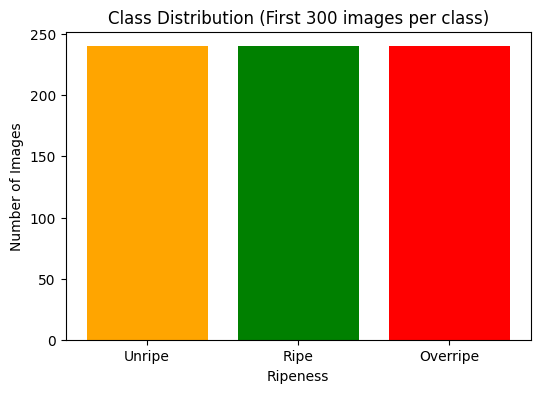

In [22]:
import matplotlib.pyplot as plt

class_counts = {}
for idx, cls in enumerate(ripeness_classes):
    class_counts[cls] = np.sum(y_train == idx)

plt.figure(figsize=(6,4))
plt.bar(class_counts.keys(), class_counts.values(), color=['orange','green','red'])
plt.title("Class Distribution (First 300 images per class)")
plt.xlabel("Ripeness")
plt.ylabel("Number of Images")
plt.show()


In [23]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


In [24]:
input_shape = (*IMG_SIZE, 3)
num_classes = len(ripeness_classes)

model = models.Sequential([
    layers.Input(shape=input_shape),
    data_augmentation,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
early_stopper = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
)

steps_per_epoch = len(x_train) // BATCH_SIZE
validation_steps = len(x_val) // BATCH_SIZE

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=[early_stopper]
)


Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 34s 657ms/step - accuracy: 0.4525 - loss: 1.0063 - val_accuracy: 0.8011 - val_loss: 0.6352
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.7444 - loss: 0.6136 - val_accuracy: 0.7670 - val_loss: 0.5622
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 549ms/step - accuracy: 0.8204 - loss: 0.4670 - val_accuracy: 0.8693 - val_loss: 0.4437
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 41s 545ms/step - accuracy: 0.8343 - loss: 0.4311 - val_accuracy: 0.8750 - val_loss: 0.4182
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 538ms/step - accuracy: 0.8200 - loss: 0.4819 - val_accuracy: 0.8693 - val_loss: 0.4305
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 41s 921ms/step - accuracy: 0.8470 - loss: 0.4460 - val_accuracy: 0.8693 - val_loss: 0.4415
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 63s 499ms/step - accuracy: 0.8441 - loss: 0.4205 - val_accuracy: 0.8693 - val_loss: 0.4298
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.8741 - loss: 0.3495 - val_accuracy: 

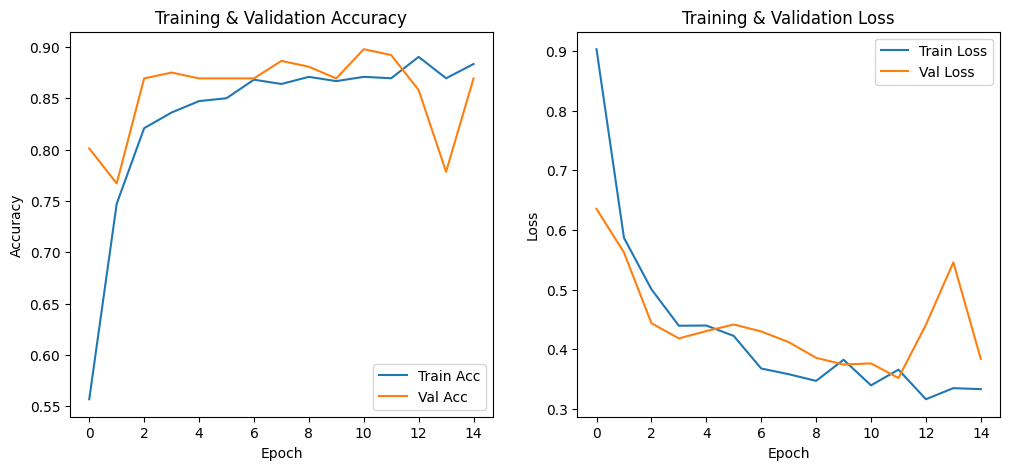

In [26]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


In [27]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.7945 - loss: 0.7244
Test Accuracy: 67.22%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step


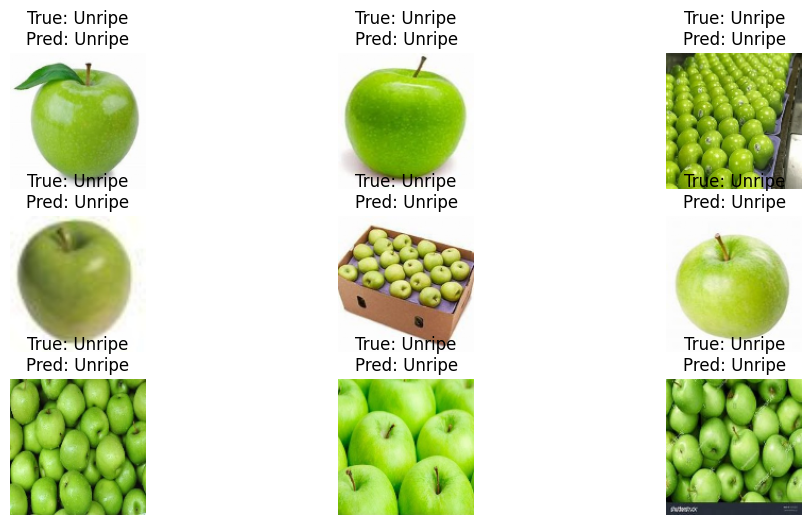

In [28]:
for images, labels in test_ds.take(1):
    preds = model.predict(images)
    pred_labels = np.argmax(preds, axis=1)

    plt.figure(figsize=(12,6))
    for i in range(min(9, images.shape[0])):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy())
        plt.title(f"True: {ripeness_classes[labels[i]]}\nPred: {ripeness_classes[pred_labels[i]]}")
        plt.axis('off')
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
              precision    recall  f1-score   support

      Unripe       0.84      0.97      0.90        60
        Ripe       0.56      0.47      0.51        60
    Overripe       0.57      0.58      0.58        60

    accuracy                           0.67       180
   macro avg       0.66      0.67      0.66       180
weighted avg       0.66      0.67      0.66       180



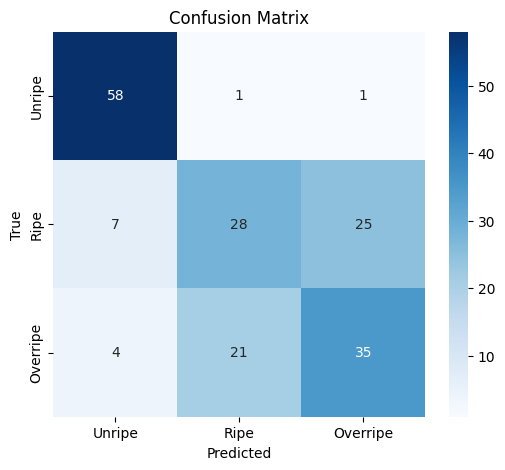

In [29]:
# Predict all test images
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

print(classification_report(y_true, y_pred, target_names=ripeness_classes))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=ripeness_classes, yticklabels=ripeness_classes, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [30]:
model.save("fruit_ripeness_cnn_model.h5")
print("Model saved as fruit_ripeness_cnn_model.h5")


Model saved as fruit_ripeness_cnn_model.h5
